# scRNA-seq Analysis: t96 vs t120

**Samples:**
- `GSM8448423_t96.h5` 
- `GSM8448424_t120_dox96-G.h5`
- `GSM8448425_t120_dox96-R.h5`


In [1]:
import os
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib


sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=100, facecolor='white', frameon=False)
matplotlib.rcParams['figure.figsize'] = (6, 5)

os.makedirs('results', exist_ok=True)
sc.settings.figdir = './results/'   

print('scanpy version:', sc.__version__)

scanpy version: 1.11.5


/var/folders/b3/w_5chnbj6rb6k9r3gbwrlw140000gn/T/ipykernel_54382/448268516.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print('scanpy version:', sc.__version__)


## Load data

In [2]:
# Load each sample — keep 'sample' label so Scrublet runs per independent 10x run
adata_t96 = sc.read_10x_h5('data/GSM8448423_t96.h5')
adata_t96.obs['timepoint'] = 't96'
adata_t96.obs['sample']    = 't96'
adata_t96.var_names_make_unique()
adata_t96.obs_names = [f't96_{bc}' for bc in adata_t96.obs_names]
print('t96:', adata_t96.shape)

adata_t120_G = sc.read_10x_h5('data/GSM8448424_t120_dox96-G.h5')
adata_t120_G.obs['timepoint'] = 't120'
adata_t120_G.obs['sample']    = 't120_G'
adata_t120_G.var_names_make_unique()
adata_t120_G.obs_names = [f't120G_{bc}' for bc in adata_t120_G.obs_names]
print('t120 dox96-G:', adata_t120_G.shape)

adata_t120_R = sc.read_10x_h5('data/GSM8448425_t120_dox96-R.h5')
adata_t120_R.obs['timepoint'] = 't120'
adata_t120_R.obs['sample']    = 't120_R'
adata_t120_R.var_names_make_unique()
adata_t120_R.obs_names = [f't120R_{bc}' for bc in adata_t120_R.obs_names]
print('t120 dox96-R:', adata_t120_R.shape)


/Users/huiting/miniconda3/envs/sc/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/huiting/miniconda3/envs/sc/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


t96: (3496, 32290)


/Users/huiting/miniconda3/envs/sc/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/huiting/miniconda3/envs/sc/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


t120 dox96-G: (3168, 32290)
t120 dox96-R: (2361, 32290)


/Users/huiting/miniconda3/envs/sc/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/huiting/miniconda3/envs/sc/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [3]:
# Merge all three into one AnnData object
adata = sc.concat(
    [adata_t96, adata_t120_G, adata_t120_R],
    join='outer'   # keeps only genes present in all samples
)
adata.var_names_make_unique()
print('Combined:', adata.shape)
print(adata.obs['timepoint'].value_counts())
print(len(adata.var_names))

Combined: (9025, 32290)
timepoint
t120    5529
t96     3496
Name: count, dtype: int64
32290


## Quality Control

mt- genes in dataset: 13
       n_genes_by_counts  total_counts  pct_counts_mt
count            9025.00       9025.00        9025.00
mean             4374.92      18985.35           2.92
std              1441.38      10584.60           4.98
min               169.00        503.00           0.00
25%              3698.00      12467.00           1.56
50%              4514.00      17961.00           1.88
75%              5269.00      23745.00           2.26
max              8272.00      75069.00          69.10


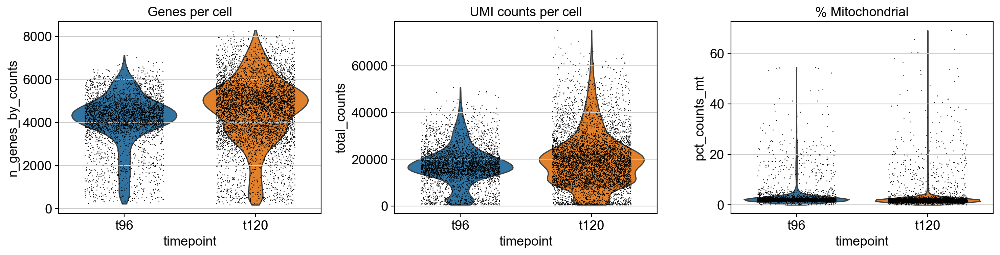

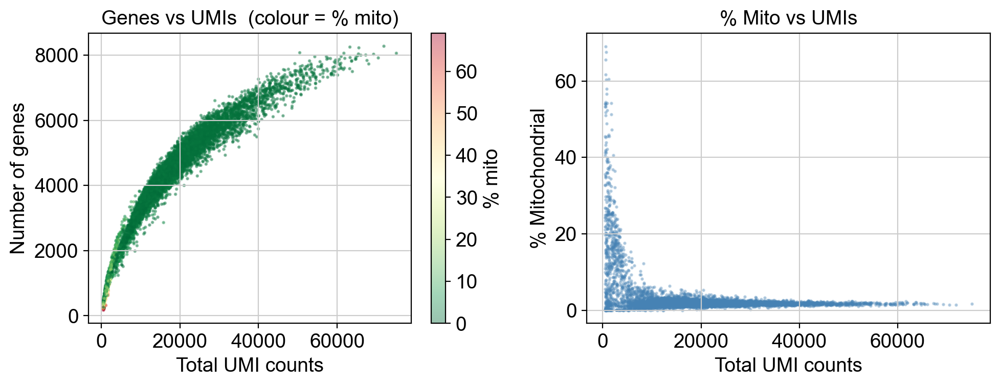

In [4]:
# mitochondrial genes
adata.var['mt'] = adata.var_names.str.startswith('mt-')
print(f'mt- genes in dataset: {adata.var["mt"].sum()}')  # 13 in mouse

sc.pp.calculate_qc_metrics(
    adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True
)

print(adata.obs[['n_genes_by_counts', 'total_counts', 'pct_counts_mt']]
      .describe().round(2))

# ── Violin plots ───────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sc.pl.violin(adata, 'n_genes_by_counts', groupby='timepoint',
             jitter=0.3, ax=axes[0], show=False)
axes[0].set_title('Genes per cell')

sc.pl.violin(adata, 'total_counts', groupby='timepoint',
             jitter=0.3, ax=axes[1], show=False)
axes[1].set_title('UMI counts per cell')

sc.pl.violin(adata, 'pct_counts_mt', groupby='timepoint',
             jitter=0.3, ax=axes[2], show=False)
axes[2].set_title('% Mitochondrial')

plt.tight_layout()
plt.savefig('results/qc_violin.png', dpi=150, bbox_inches='tight')
plt.show()




# ── Scatter plots ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sc.plot = axes[0].scatter(adata.obs['total_counts'], adata.obs['n_genes_by_counts'],
                c=adata.obs['pct_counts_mt'], cmap='RdYlGn_r', s=2, alpha=0.4)
axes[0].set_xlabel('Total UMI counts')
axes[0].set_ylabel('Number of genes')
axes[0].set_title('Genes vs UMIs  (colour = % mito)')
plt.colorbar(axes[0].collections[0], ax=axes[0], label='% mito')

axes[1].scatter(adata.obs['total_counts'], adata.obs['pct_counts_mt'],
                s=2, alpha=0.3, color='steelblue')
axes[1].set_xlabel('Total UMI counts')
axes[1].set_ylabel('% Mitochondrial')
axes[1].set_title('% Mito vs UMIs')



plt.tight_layout()
plt.savefig('results/qc_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
min_genes      = 500
max_genes      = 8000
min_cells_gene = 3
max_mito       = 20


print('Before filtering:', adata.shape)
sc.pp.filter_cells(adata, min_genes=min_genes)
sc.pp.filter_genes(adata, min_cells=min_cells_gene)
adata = adata[adata.obs['n_genes_by_counts'] < max_genes].copy()
adata = adata[adata.obs['pct_counts_mt'] < max_mito].copy()
print('After filtering: ', adata.shape)
print(f'\nCells per timepoint after QC:')
print(adata.obs['timepoint'].value_counts())

Before filtering: (9025, 32290)
After filtering:  (8782, 19285)

Cells per timepoint after QC:
timepoint
t120    5384
t96     3398
Name: count, dtype: int64


## Doublet Detection

In [6]:
# Run Scrublet per sample (t96, t120_G, t120_R) using raw counts to detect doublets
sc.pp.scrublet(adata, batch_key='sample') #nearest-neighbor classifiet
print('Predicted doublets per sample:')
print(adata.obs.groupby('sample')['predicted_doublet'].value_counts())
print(f'\nTotal predicted doublets: {adata.obs["predicted_doublet"].sum()}')
print(f'Doublet rate: {adata.obs["predicted_doublet"].mean()*100:.1f}%')


# ── Remove predicted doublets ──────────────────────────────────────────────────
n_before = adata.n_obs
adata = adata[~adata.obs['predicted_doublet']].copy()
print(f'\nRemoved {n_before - adata.n_obs} doublets')
print('Cells remaining:', adata.obs['timepoint'].value_counts().to_dict())

Predicted doublets per sample:
sample  predicted_doublet
t120_G  False                3081
t120_R  False                2302
        True                    1
t96     False                3393
        True                    5
Name: count, dtype: int64

Total predicted doublets: 6
Doublet rate: 0.1%

Removed 6 doublets
Cells remaining: {'t120': 5383, 't96': 3393}


## Normalisation

Highly variable genes: 3739


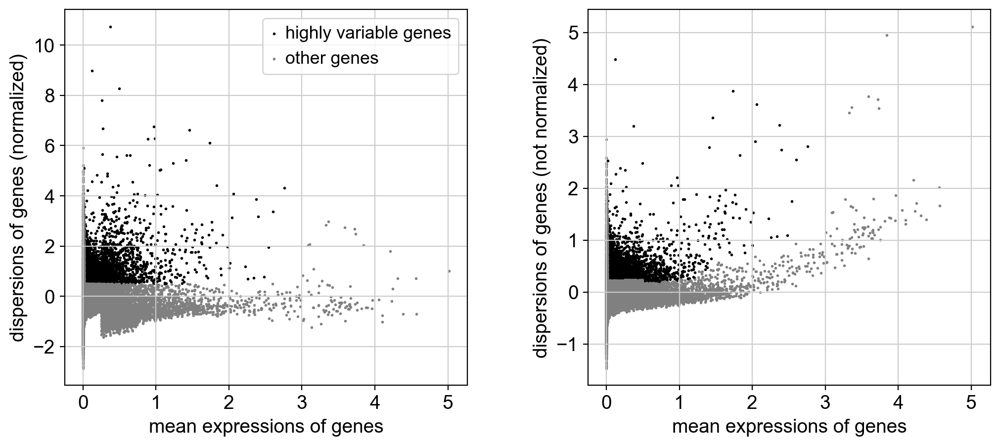

In [7]:
# Store raw counts before normalisation
adata.layers['counts'] = adata.X.copy()

# Normalize the data to 10,000 reads
sc.pp.normalize_total(adata, target_sum=1e4)
# Log transform the data
sc.pp.log1p(adata)
adata.raw = adata 

sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
print(f'Highly variable genes: {adata.var.highly_variable.sum()}')
sc.pl.highly_variable_genes(adata)

## Clustering

/Users/huiting/miniconda3/envs/sc/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


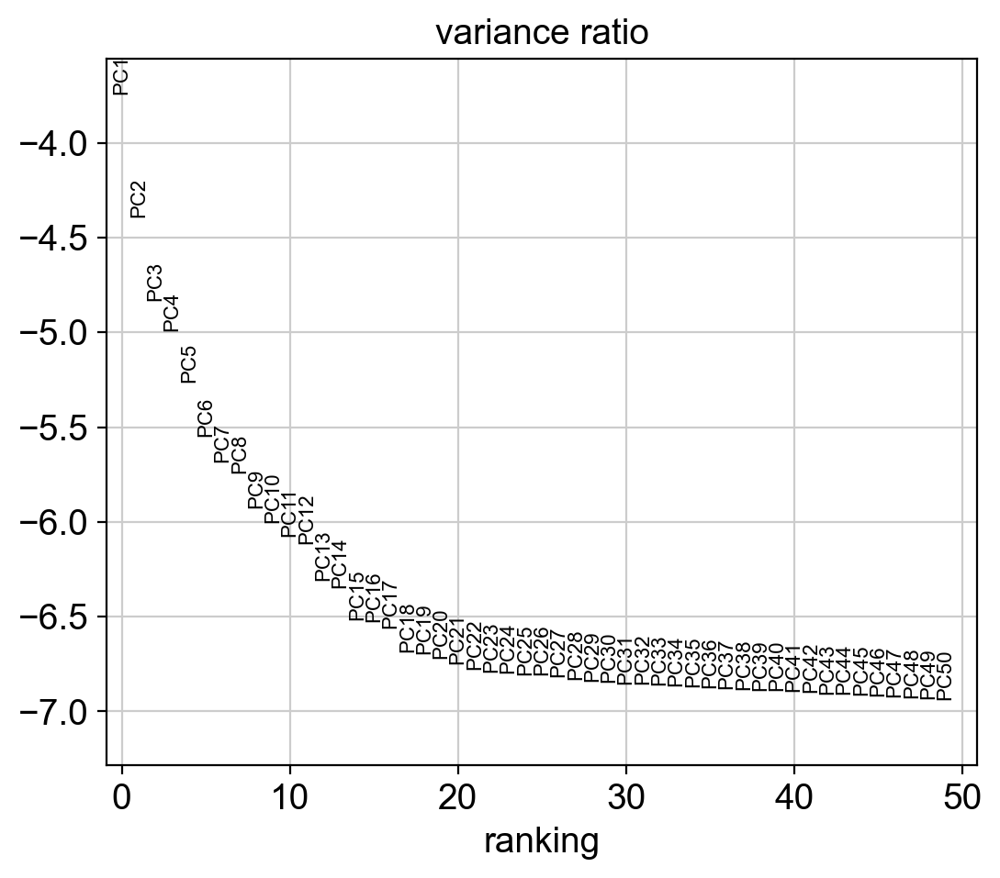

In [8]:
adata_hvg = adata[:, adata.var.highly_variable].copy()

sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg, svd_solver='arpack', n_comps=50)
sc.pl.pca_variance_ratio(adata_hvg, n_pcs=50, log=True)

In [9]:
n_pcs = 40   # adjust based on elbow plot above
sc.pp.neighbors(adata_hvg, n_neighbors=20, n_pcs=n_pcs)
sc.tl.umap(adata_hvg)

# Leiden clustering
sc.tl.leiden(adata_hvg, resolution=0.5, key_added='leiden')

# Copy UMAP and clustering back to full adata
adata.obsm['X_umap'] = adata_hvg.obsm['X_umap']
adata.obs['leiden'] = adata_hvg.obs['leiden']

print('Clusters found:', adata.obs['leiden'].nunique())

/Users/huiting/miniconda3/envs/sc/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/b3/w_5chnbj6rb6k9r3gbwrlw140000gn/T/ipykernel_54382/3734241101.py:6: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_hvg, resolution=0.5, key_added='leiden')


Clusters found: 8


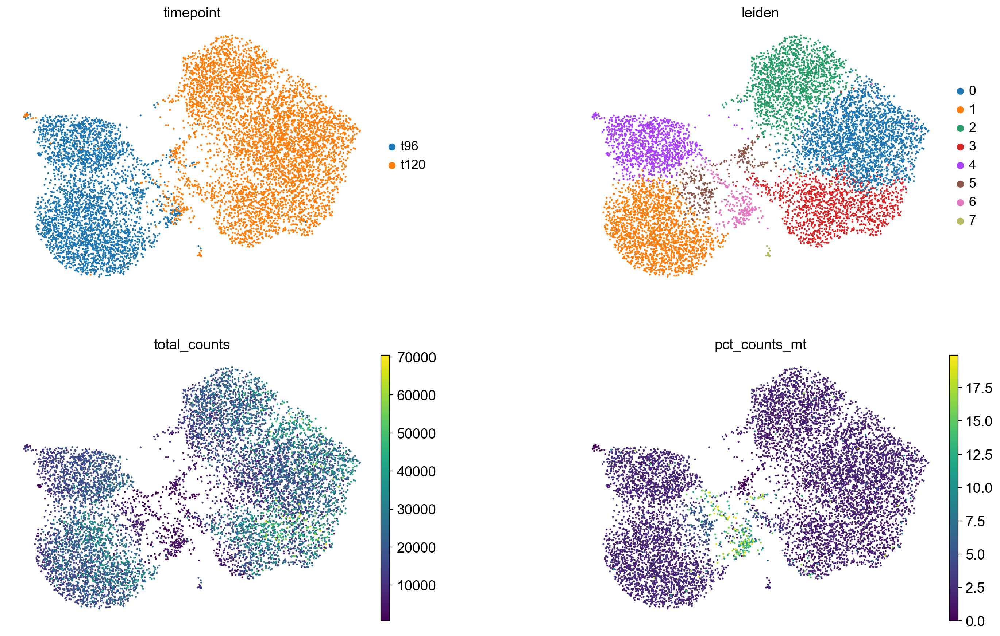

In [ ]:
sc.pl.umap(adata, color=['timepoint', 'leiden', 'total_counts', 'pct_counts_mt'],
           ncols=2, wspace=0.4,save='_qc_overview.png')

plt.show()

Removed 257 cells in clusters {'7', '6', '9', '8'}
Cells remaining: 8519
leiden
0    2327
1    1925
2    1521
3    1305
4    1140
5     301
Name: count, dtype: int64


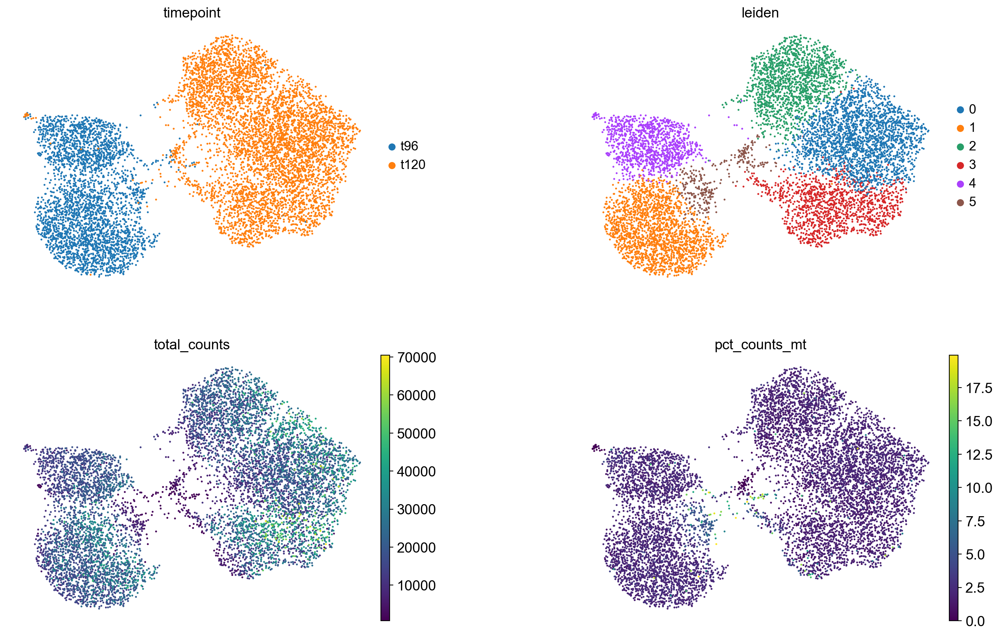

In [11]:
# Remove low-quality clusters
remove_clusters = {'6','7', '8', '9'}
n_before = adata.n_obs
adata = adata[~adata.obs['leiden'].isin(remove_clusters)].copy()
print(f'Removed {n_before - adata.n_obs} cells in clusters {remove_clusters}')
print('Cells remaining:', adata.n_obs)
print(adata.obs['leiden'].value_counts())
sc.pl.umap(adata, color=['timepoint', 'leiden', 'total_counts', 'pct_counts_mt'],
           ncols=2, wspace=0.4,save='_qc_overview_removed.png')

plt.show()

## Gene Expression of Interest genes

Visualise the GOI list on the UMAP and compare expression levels across gastruloid cell types.

Found 43/61 genes
Not in dataset: ['Ereg', 'Mmp1', 'Mmp3', 'Mmp4', 'Mmp5', 'Mmp6', 'Mmp8', 'Mmp10', 'Mmp12', 'Mmp13', 'Mmp18', 'Mmp20', 'Mmp21', 'Mmp22', 'Mmp26', 'Mmp27', 'Mmp29', 'Tbxt']


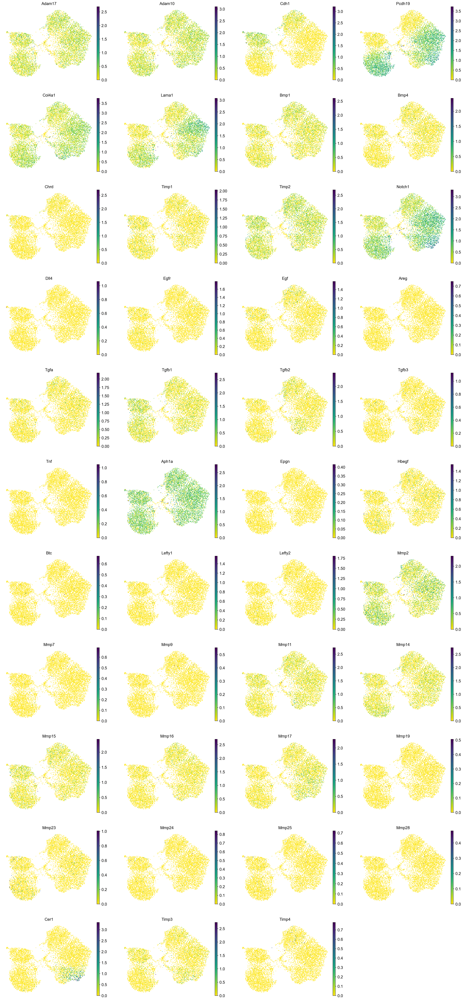

In [12]:
# Genes of interest — mouse names (human ALL CAPS → mouse Title case)
gene_list = [
    'Adam17','Adam10','Cdh1','Pcdh19','Col4a1','Lama1',
    'Bmp1','Bmp4','Chrd','Timp1','Timp2','Notch1','Dll4',
    'Egfr','Egf','Areg','Ereg','Tgfa','Tgfb1','Tgfb2',
    'Tgfb3','Tnf','Aph1a','Epgn','Hbegf','Btc','Lefty1','Lefty2',
    'Mmp1','Mmp2','Mmp3','Mmp4','Mmp5','Mmp6','Mmp7','Mmp8','Mmp9','Mmp10',
    'Mmp11','Mmp12','Mmp13','Mmp14','Mmp15','Mmp16','Mmp17','Mmp18','Mmp19',
    'Mmp20','Mmp21','Mmp22','Mmp23','Mmp24','Mmp25','Mmp26','Mmp27','Mmp28',
    'Mmp29','Cer1','Timp3','Timp4','Tbxt',
]

gene_found   = [g for g in gene_list if g in adata.var_names]
gene_missing = [g for g in gene_list if g not in adata.var_names]
print(f'Found {len(gene_found)}/{len(gene_list)} genes')
if gene_missing:
    print('Not in dataset:', gene_missing)

# UMAP — one panel per gene, coloured by expression
sc.pl.umap(adata, color=gene_found, ncols=4,
           use_raw=True, cmap='viridis_r', vmin=0, frameon=False,
           save='_gi_umap.png')
plt.show()

## Genes Most Differentially Expressed

Global Wilcoxon test (all cells, t120 vs t96). Top genes by absolute score are shown on UMAP.

Significant DE genes: 7642

Top by fold change (biggest difference between t96 and t120):
       names  logfoldchanges      pvals_adj
853   Hoxc10       26.284021   1.498416e-31
6134    Pax1        6.519001   3.235913e-02
1454    Uncx        6.314525   1.692799e-19
4863    Bmp3        6.284464   6.581676e-04
5645   Grem1        6.077568   9.694573e-03
3633  Hoxa10        5.980793   1.212360e-06
5311   Foxd2        5.949266   3.279148e-03
7602  Pou5f1       -5.547520   0.000000e+00
1351    Islr        5.485162   1.076486e-20
205   Igfbp5        5.176278   1.325317e-92
38     Hoxa9        4.861071  3.951945e-235
6768   Dppa2       -4.817392   1.381232e-04
6890   Trpm1       -4.799090   2.765679e-06
4349   Lrrn3        4.733517   7.796494e-05
7      Hoxd9        4.653064   0.000000e+00
3677     Hpd        4.637353   1.586871e-06
7596   Foxh1       -4.602901   0.000000e+00
3553   Meox2        4.588242   6.680078e-07
2854    Cer1        4.482952   1.851875e-09
359   Cxcl12        4.420814  

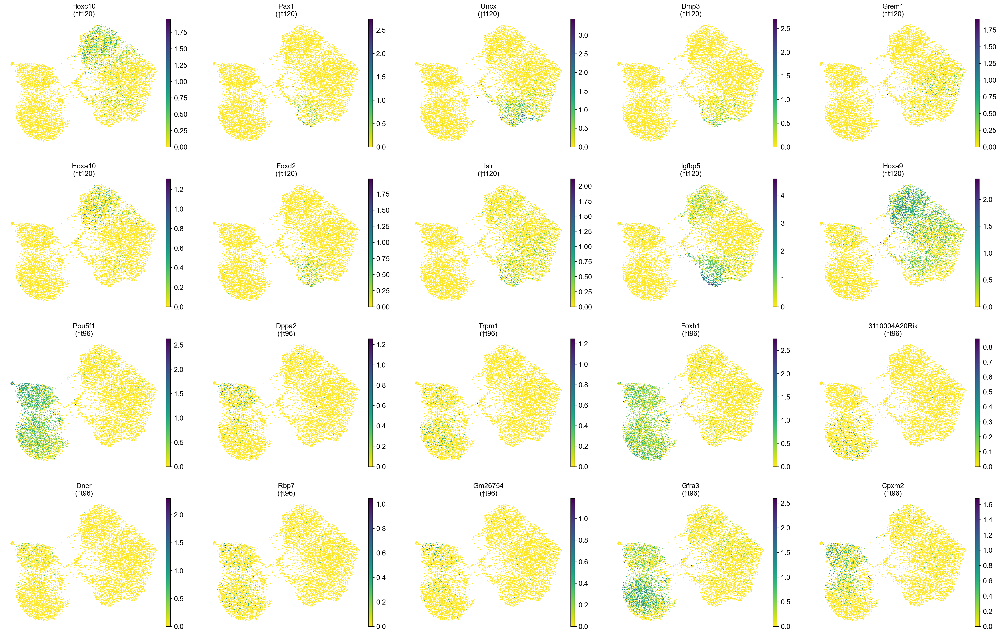

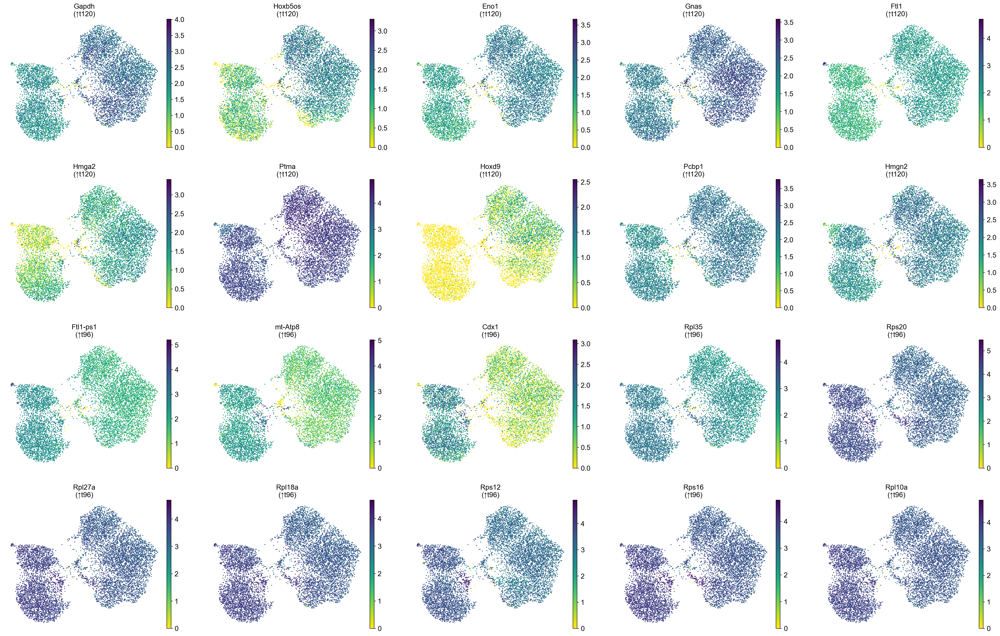


Genes in both top-20 lists (big effect + consistent): []


In [13]:
# ── Global DE: t120 vs t96 ────────────────────────────────────────────────────
sc.tl.rank_genes_groups(
    adata, groupby='timepoint',
    groups=['t120'], reference='t96',
    method='wilcoxon', use_raw=True,
    key_added='de_timepoint'
)

de_df = sc.get.rank_genes_groups_df(
    adata, group='t120', key='de_timepoint', pval_cutoff=0.05
)

by_fc    = de_df.sort_values('logfoldchanges', key=abs, ascending=False)
by_score = de_df.sort_values('scores',         key=abs, ascending=False)

print(f"Significant DE genes: {len(de_df)}")
print("\nTop by fold change (biggest difference between t96 and t120):")
print(by_fc.head(20)[['names', 'logfoldchanges', 'pvals_adj']])
print("\nTop by score (most consistent shift across all cells):")
print(by_score.head(20)[['names', 'logfoldchanges', 'pvals_adj']])

de_df.to_csv('results/DE_t120_vs_t96_global.csv', index=False)

# ── UMAP: top genes by fold change ───────────────────────────────────────────
fc_up   = by_fc[by_fc['logfoldchanges'] > 0]['names'].head(10).tolist()
fc_down = by_fc[by_fc['logfoldchanges'] < 0]['names'].head(10).tolist()
fc_genes = [g for g in fc_up + fc_down if g in adata.var_names]

sc.pl.umap(
    adata, color=fc_genes,
    use_raw=True, cmap='viridis_r', ncols=5, vmin=0, frameon=False,
    title=[f"{g}\n({'↑t120' if g in fc_up else '↑t96'})" for g in fc_genes],
    save='_de_by_foldchange_umap.png'
)
plt.show()

# ── UMAP: top genes by score ──────────────────────────────────────────────────
sc_up   = by_score[by_score['logfoldchanges'] > 0]['names'].head(10).tolist()
sc_down = by_score[by_score['logfoldchanges'] < 0]['names'].head(10).tolist()
sc_genes = [g for g in sc_up + sc_down if g in adata.var_names]

sc.pl.umap(
    adata, color=sc_genes,
    use_raw=True, cmap='viridis_r', ncols=5, vmin=0, frameon=False,
    title=[f"{g}\n({'↑t120' if g in sc_up else '↑t96'})" for g in sc_genes],
    save='_de_by_score_umap.png'
)
plt.show()

# ── Genes in both top lists ───────────────────────────────────────────────────
overlap = set(by_fc['names'].head(20)) & set(by_score['names'].head(20))
print(f"\nGenes in both top-20 lists (big effect + consistent): {sorted(overlap)}")


In [14]:
de_df.sort_values('scores', key=abs, ascending=False)

,names,scores,logfoldchanges,pvals,pvals_adj
7641,Ftl1-ps1,-69.647591,-1.265348,0.000000,0.000000
7640,mt-Atp8,-67.663811,-1.806691,0.000000,0.000000
7639,Cdx1,-66.961563,-2.682513,0.000000,0.000000
0,Gapdh,66.383682,1.091199,0.000000,0.000000
7638,Rpl35,-63.218021,-0.810453,0.000000,0.000000
...,...,...,...,...,...
6330,Cdkn3,-2.331521,-0.273829,0.019726,0.049805
6326,Ngrn,2.331236,0.100381,0.019741,0.049837
6327,Pkp4,2.331136,0.124803,0.019746,0.049844
6328,Foxo3,2.331005,0.121730,0.019753,0.049855


---
## t120_G vs t120_R Analysis

Subset to t120 cells only, re-cluster, and find DE genes between the two t120 dox96-G vs dox96-R.

In [15]:
# ── Subset to t120 cells ──────────────────────────────────────────────────────
adata_t120 = adata[adata.obs['timepoint'] == 't120'].copy()
print('t120 cells:', adata_t120.shape)
print(adata_t120.obs['sample'].value_counts())


t120 cells: (5249, 19285)
sample
t120_G    3016
t120_R    2233
Name: count, dtype: int64


### Re-cluster t120 subset

Highly variable genes: 3481


/Users/huiting/miniconda3/envs/sc/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


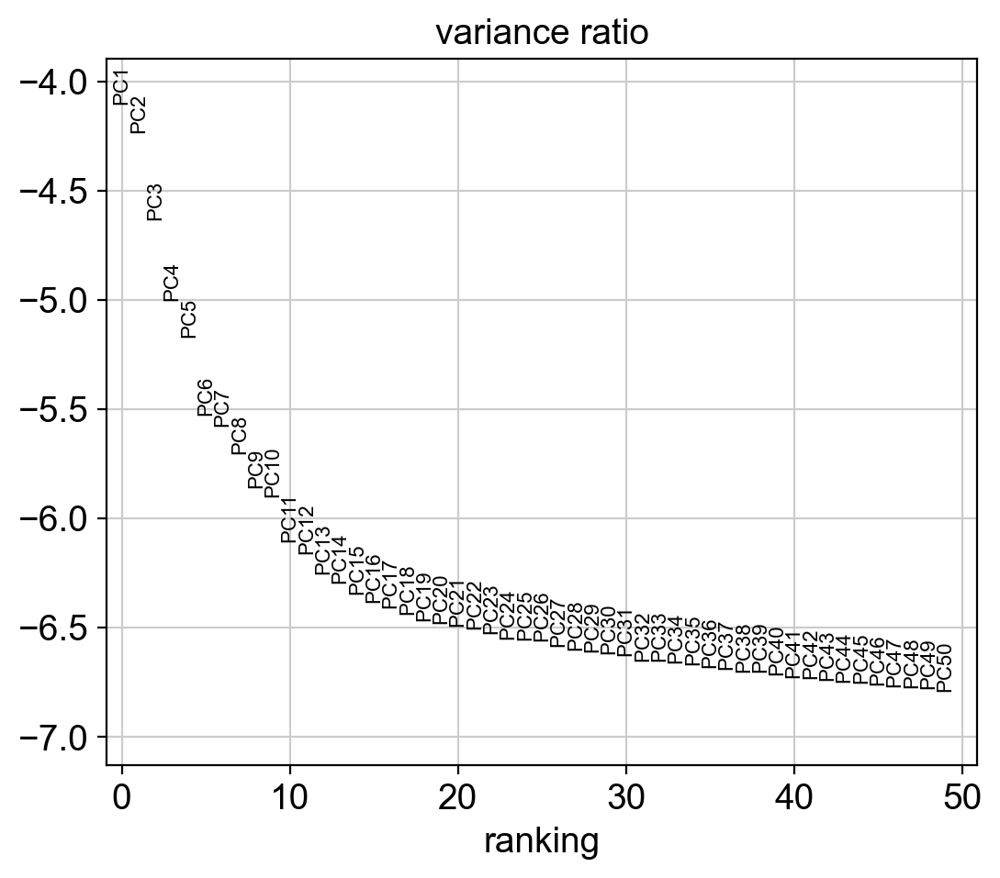

In [16]:
# Re-run HVG → PCA → neighbours → UMAP → Leiden on t120 subset only
sc.pp.highly_variable_genes(adata_t120, min_mean=0.0125, max_mean=3, min_disp=0.5)
print(f'Highly variable genes: {adata_t120.var.highly_variable.sum()}')

adata_t120_hvg = adata_t120[:, adata_t120.var.highly_variable].copy()
sc.pp.scale(adata_t120_hvg, max_value=10)
sc.tl.pca(adata_t120_hvg, svd_solver='arpack', n_comps=50)
sc.pl.pca_variance_ratio(adata_t120_hvg, n_pcs=50, log=True)


Clusters found: 7


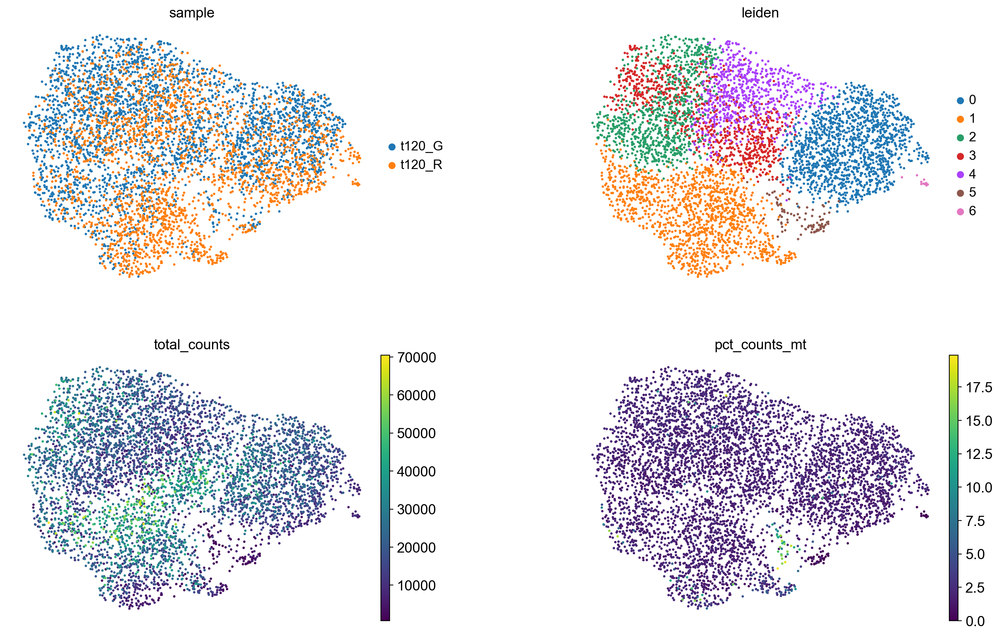

In [17]:
n_pcs_t120 = 40

sc.pp.neighbors(adata_t120_hvg, n_neighbors=20, n_pcs=n_pcs_t120)
sc.tl.umap(adata_t120_hvg)
sc.tl.leiden(adata_t120_hvg, resolution=0.5, key_added='leiden')

# Copy UMAP and clusters back to adata_t120
adata_t120.obsm['X_umap'] = adata_t120_hvg.obsm['X_umap']
adata_t120.obs['leiden']  = adata_t120_hvg.obs['leiden']

print('Clusters found:', adata_t120.obs['leiden'].nunique())
sc.pl.umap(adata_t120, color=['sample', 'leiden','total_counts', 'pct_counts_mt'], ncols=2, wspace=0.4,
           save='_t120_clusters.png')
plt.show()


### Genes of Interest — t120 subset

Found 43/61 genes
Not in dataset: ['Ereg', 'Mmp1', 'Mmp3', 'Mmp4', 'Mmp5', 'Mmp6', 'Mmp8', 'Mmp10', 'Mmp12', 'Mmp13', 'Mmp18', 'Mmp20', 'Mmp21', 'Mmp22', 'Mmp26', 'Mmp27', 'Mmp29', 'Tbxt']


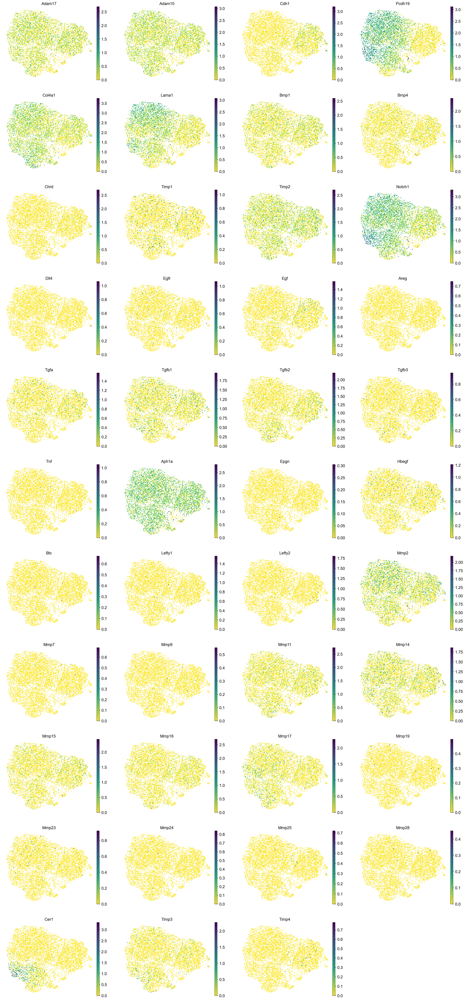

In [18]:
gene_list = [
    'Adam17','Adam10','Cdh1','Pcdh19','Col4a1','Lama1',
    'Bmp1','Bmp4','Chrd','Timp1','Timp2','Notch1','Dll4',
    'Egfr','Egf','Areg','Ereg','Tgfa','Tgfb1','Tgfb2',
    'Tgfb3','Tnf','Aph1a','Epgn','Hbegf','Btc','Lefty1','Lefty2',
    'Mmp1','Mmp2','Mmp3','Mmp4','Mmp5','Mmp6','Mmp7','Mmp8','Mmp9','Mmp10',
    'Mmp11','Mmp12','Mmp13','Mmp14','Mmp15','Mmp16','Mmp17','Mmp18','Mmp19',
    'Mmp20','Mmp21','Mmp22','Mmp23','Mmp24','Mmp25','Mmp26','Mmp27','Mmp28',
    'Mmp29','Cer1','Timp3','Timp4','Tbxt',
]

gene_list_found   = [g for g in gene_list if g in adata_t120.var_names]
gene_list_missing = [g for g in gene_list if g not in adata_t120.var_names]
print(f'Found {len(gene_list_found)}/{len(gene_list)} genes')
if gene_list_missing:
    print('Not in dataset:', gene_list_missing)

sc.pl.umap(adata_t120, color=gene_list_found, ncols=4,
           use_raw=True, cmap='viridis_r', vmin=0, frameon=False,
           save='_t120_goi_umap.png')
plt.show()


### DE: t120_G vs t120_R — top by logFC and top by score

In [19]:
sc.tl.rank_genes_groups(
    adata_t120, groupby='sample',
    groups=['t120_G'], reference='t120_R',
    method='wilcoxon', use_raw=True,
    key_added='de_G_vs_R'
)

de_GR = sc.get.rank_genes_groups_df(
    adata_t120, group='t120_G', key='de_G_vs_R', pval_cutoff=0.05
)

by_fc    = de_GR.sort_values('logfoldchanges', key=abs, ascending=False)
by_score = de_GR.sort_values('scores',         key=abs, ascending=False)

print(f'Significant DE genes: {len(de_GR)}')
print('\nTop by fold change (most different between G and R):')
print(by_fc.head(20)[['names', 'logfoldchanges', 'pvals_adj']])
print('\nTop by score (most consistent shift):')
print(by_score.head(20)[['names', 'logfoldchanges', 'pvals_adj']])

de_GR.to_csv('results/DE_t120G_vs_t120R.csv', index=False)

overlap = set(by_fc['names'].head(20)) & set(by_score['names'].head(20))
print(f'\nGenes in both top-20 lists: {sorted(overlap)}')


Significant DE genes: 9433

Top by fold change (most different between G and R):
                   names  logfoldchanges     pvals_adj
9177                Pax1       -2.231696  2.169723e-02
9232               Nr2f1       -2.074757  1.653867e-03
9193               Foxd2       -2.071376  1.160428e-02
0     Stoplight_Recorder        1.751655  0.000000e+00
9275             Foxd2os       -1.724969  7.892519e-05
9234               Meox2       -1.705827  1.254333e-03
9282              Prss23       -1.678706  1.321682e-05
9242       2610016A17Rik       -1.494836  7.002526e-04
9364              Igfbp5       -1.459590  2.640820e-21
8720               Paqr9        1.268106  1.703322e-02
9142                Dgkg        1.162523  4.783845e-02
9164               Halr1       -1.159228  3.752726e-02
8940               Lrrn2        1.101752  2.869693e-02
8469              Nt5dc3        1.043533  8.082959e-03
9248                Uncx       -1.024436  5.288626e-04
8676                Evpl        1.01891

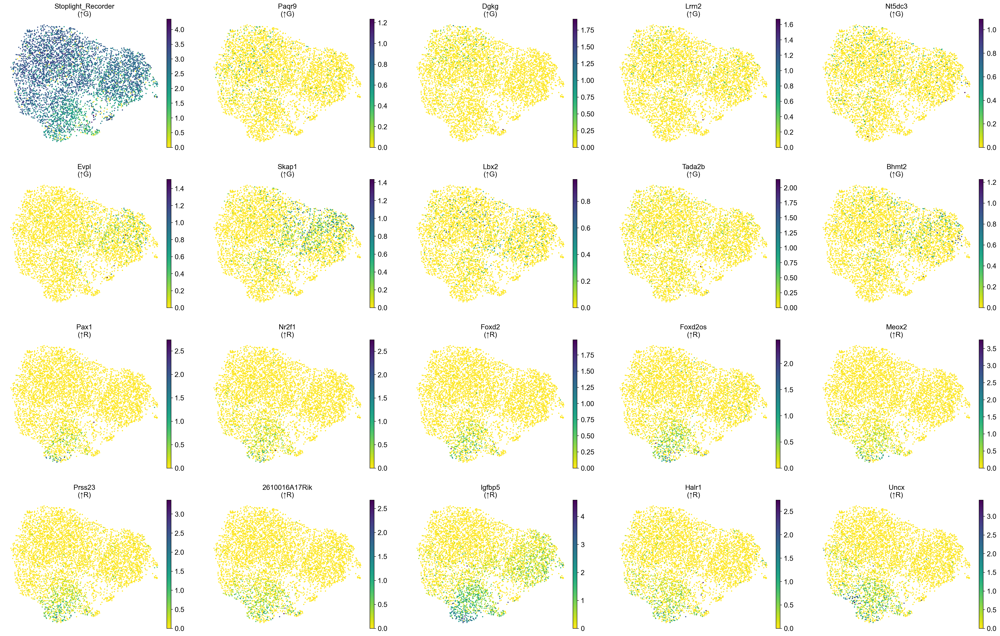

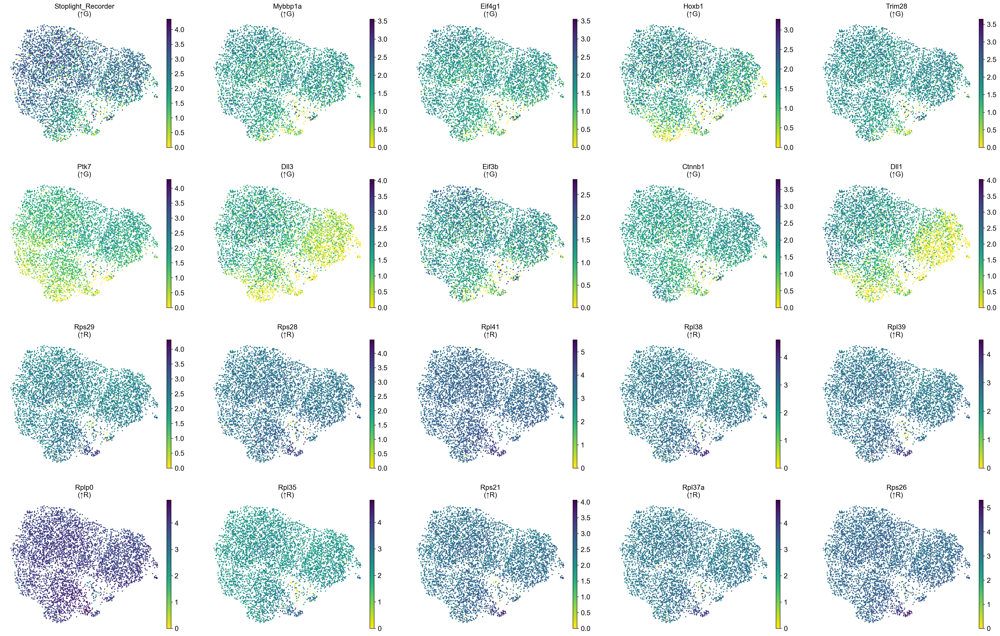

In [20]:
# ── UMAP: top genes by fold change ───────────────────────────────────────────
fc_up   = by_fc[by_fc['logfoldchanges'] > 0]['names'].head(10).tolist()
fc_down = by_fc[by_fc['logfoldchanges'] < 0]['names'].head(10).tolist()
fc_genes = [g for g in fc_up + fc_down if g in adata_t120.var_names]

sc.pl.umap(
    adata_t120, color=fc_genes,
    use_raw=True, cmap='viridis_r', ncols=5, vmin=0, frameon=False,
    title=[f"{g}\n({'↑G' if g in fc_up else '↑R'})" for g in fc_genes],
    save='_t120_de_by_foldchange_umap.png'
)
plt.show()

# ── UMAP: top genes by score ──────────────────────────────────────────────────
sc_up   = by_score[by_score['logfoldchanges'] > 0]['names'].head(10).tolist()
sc_down = by_score[by_score['logfoldchanges'] < 0]['names'].head(10).tolist()
sc_genes = [g for g in sc_up + sc_down if g in adata_t120.var_names]

sc.pl.umap(
    adata_t120, color=sc_genes,
    use_raw=True, cmap='viridis_r', ncols=5, vmin=0, frameon=False,
    title=[f"{g}\n({'↑G' if g in sc_up else '↑R'})" for g in sc_genes],
    save='_t120_de_by_score_umap.png'
)
plt.show()
